# Class 23 — Sentiment Analysis with RNN, LSTM & GRU

**Goal:** Train a model to predict whether an IMDb movie review is **positive (1)** or **negative (0)**.

We will use the **full IMDb dataset** and learn the process step by step: words → word IDs → embeddings → RNN → training → LSTM/GRU → predictions.

**Environment:** Kaggle Notebook. The notebook loads the CSV directly from the Kaggle dataset path. Turn on a GPU accelerator in Kaggle Settings if available; the full experiments take substantially longer on CPU.

## 1. Load the IMDb reviews

The file contains a `review` column (movie-review text) and a `sentiment` column (`positive` or `negative`). We will use the complete dataset, not a classroom sample.

In [42]:
import pandas as pd  # Read and inspect the IMDb CSV file.

# Load all reviews from the attached Kaggle dataset.
data = pd.read_csv("/kaggle/input/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews/IMDB Dataset.csv")

data["sentiment"] = data["sentiment"].map({"negative": 0, "positive": 1})  # Turn labels into 0 and 1.

print("Total reviews:", len(data))  # Confirm that the full dataset is loaded.
print(data["sentiment"].value_counts())  # Count reviews in each sentiment class.
display(data.head())  # Show five reviews and their labels.

Total reviews: 50000
sentiment
1    25000
0    25000
Name: count, dtype: int64


,review,sentiment
0,One of the other reviewers has mentioned that ...,1
1,A wonderful little production. <br /><br />The...,1
2,I thought this was a wonderful way to spend ti...,1
3,Basically there's a family where a little boy ...,0
4,"Petter Mattei's ""Love in the Time of Money"" is...",1


## 2. Split the data

- **Training:** used to learn the model's weights.
- **Validation:** used to check each epoch and choose the best model.
- **Test:** used only after choosing the final model.

We use **72% for training, 8% for validation, and 20% for testing**. Stratified splitting keeps the positive/negative proportions approximately equal.

In [43]:
from sklearn.model_selection import train_test_split  # Split reviews into separate groups.

# Keep 20% of the reviews completely separate for the final test.
train_data, test_data = train_test_split(
    data, test_size=0.20, random_state=42, stratify=data["sentiment"]
)

# Take 10% of the remaining 80% for validation (8% of the complete data).
train_data, val_data = train_test_split(
    train_data, test_size=0.10, random_state=42, stratify=train_data["sentiment"]
)

print("Training reviews:", len(train_data))  # The model learns from these reviews.
print("Validation reviews:", len(val_data))  # Used to choose the best epoch/model.
print("Test reviews:", len(test_data))  # Kept for final evaluation.

Training reviews: 36000
Validation reviews: 4000
Test reviews: 10000


## 3. Turn a review into words

Neural networks cannot directly process a string such as `"The movie was not good!"`. We first split it into **tokens** (words).

We convert uppercase letters to lowercase and remove HTML tags. We keep apostrophes *inside words*, so **`don't` stays one token** instead of being split into `don` and `t`. This keeps the negative expression easier to recognize.

In [44]:
import re  # Work with patterns in text.

def tokenize(text):  # Convert one review into a list of words.
    text = text.lower()  # Treat "Movie" and "movie" as the same word.
    text = re.sub(r"<[^>]+>", " ", text)  # Remove HTML tags such as <br />.
    words = re.findall(r"[a-z]+(?:'[a-z]+)?", text)  # Keep "don't" as one word.
    return words  # Give back the words in their original order.

review = "The movie was not good!"  # A small example used throughout the notebook.
print("Original:", review)  # The sentence before processing.
print("Tokens:", tokenize(review))  # The sentence converted into a list of words.

Original: The movie was not good!
Tokens: ['the', 'movie', 'was', 'not', 'good']


## 4. Give each word an ID

A **vocabulary** is a dictionary such as `{"movie": 5, "good": 8}`. These numbers are identifiers, not measures of word meaning.

We build the vocabulary using **training reviews only**, and reserve `0` for `<PAD>` (empty positions) and `1` for `<UNK>` (unknown words).

In [45]:
from collections import Counter  # Count how often each word appears.

word_counts = Counter()  # Start with no word counts.
for text in train_data["review"]:  # Read each training review.
    word_counts.update(tokenize(text))  # Add its words to the counts.

word2idx = {"<PAD>": 0, "<UNK>": 1}  # Reserve IDs for padding and unknown words.
for word, count in word_counts.most_common(10000):  # Use the 10,000 most frequent words.
    word2idx[word] = len(word2idx)  # Give the next integer ID to this word.

print("Vocabulary size:", len(word2idx))  # Includes <PAD> and <UNK>.
print("Example word IDs:", [word2idx.get(w, 1) for w in tokenize(review)])  # Encode our sample.

Vocabulary size: 10002
Example word IDs: [2, 17, 13, 21, 49]


## 5. Make reviews the same length

Reviews contain different numbers of words. A batch must have the same sequence length for every review, so we:

1. Keep at most **200 words** (truncation).
2. Add `0` on the right to shorter reviews (padding).
3. Keep the **real length** so the RNN classifier can use the output after the last actual word, rather than after padding.

Longer reviews are shortened for this introductory model, so information beyond the first 200 tokens is not used.

In [46]:
MAX_LEN = 200  # Each model input will have exactly 200 word IDs.

def encode_review(text):  # Convert one review into padded IDs and its real length.
    words = tokenize(text)[:MAX_LEN]  # Keep the first 200 words at most.
    ids = [word2idx.get(word, 1) for word in words]  # Unknown words get ID 1.
    length = len(ids)  # Count words before adding padding.
    ids = ids + [0] * (MAX_LEN - length)  # Add zeros to reach 200 positions.
    return ids, length  # The model needs both the IDs and the real length.

example_ids, example_length = encode_review(review)  # Encode the running example.
print("First 10 IDs:", example_ids[:10])  # See word IDs followed by padding zeros.
print("Real words:", example_length)  # Number of actual words in the review.
print("Padded length:", len(example_ids))  # Always 200.

First 10 IDs: [2, 17, 13, 21, 49, 0, 0, 0, 0, 0]
Real words: 5
Padded length: 200


## 6. Prepare PyTorch batches

A **tensor** holds numbers for PyTorch. A `DataLoader` gives the model a small batch of reviews at a time, containing:

- `word_ids`: padded word IDs, shape `(batch_size, 200)`.
- `lengths`: actual word counts, shape `(batch_size,)`.
- `labels`: positive/negative targets, shape `(batch_size,)`.

A GPU can speed up the training of all three models on the full dataset. Kaggle can use one when an accelerator is enabled.

In [47]:
import torch  # PyTorch tensors, neural networks, and training functions.
from torch.utils.data import TensorDataset, DataLoader  # Store examples and create batches.

torch.manual_seed(42)  # Use the same random seed when initializing models.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # Use Kaggle GPU if enabled.
print("Training device:", device)  # 'cuda' means GPU; 'cpu' means CPU.

def prepare_data(reviews):  # Turn a group of movie reviews into a PyTorch dataset.
    encoded = [encode_review(text) for text in reviews["review"]]  # Encode every review.
    word_ids = torch.tensor([item[0] for item in encoded], dtype=torch.long)  # Word IDs are integers.
    lengths = torch.tensor([item[1] for item in encoded], dtype=torch.long)  # Actual word counts.
    labels = torch.tensor(reviews["sentiment"].tolist(), dtype=torch.float32)  # Binary labels.
    return TensorDataset(word_ids, lengths, labels)  # Keep the three tensors together.

train_loader = DataLoader(prepare_data(train_data), batch_size=64, shuffle=True)  # Shuffle training batches.
val_loader = DataLoader(prepare_data(val_data), batch_size=64)  # Validation batches are not shuffled.
test_loader = DataLoader(prepare_data(test_data), batch_size=64)  # Keep the test set separate.

batch_ids, batch_lengths, batch_labels = next(iter(train_loader))  # Inspect one training batch.
print("Word IDs shape:", batch_ids.shape)  # Up to 64 reviews, each padded to 200 IDs.
print("Real lengths shape:", batch_lengths.shape)  # One length for each review.
print("Labels shape:", batch_labels.shape)  # One sentiment label for each review.

Training device: cuda
Word IDs shape: torch.Size([64, 200])
Real lengths shape: torch.Size([64])
Labels shape: torch.Size([64])


## 7. Word embeddings

A word ID identifies a word, but says nothing about its meaning. `nn.Embedding` associates each word ID with a learnable vector of numbers.

At first, those vectors are initialized without useful sentiment knowledge. **They learn during training**, because the optimizer updates the embedding layer together with the recurrent model and the final classifier. We will inspect the same word's vector before and after training.

We use **100 numbers per word**, so we can later compare embeddings learned from scratch with **100-dimensional pretrained GloVe vectors**.

In [48]:
from torch import nn  # Ready-made neural network layers.

embedding = nn.Embedding(len(word2idx), 100, padding_idx=0)  # Give each word a vector of 100 numbers.
small_batch = batch_ids[:2]  # Use just two reviews to understand the shape.
vectors = embedding(small_batch)  # Convert each integer ID into its embedding vector.
print("IDs shape:", small_batch.shape)  # (2, 200): 2 reviews with 200 IDs each.
print("Embeddings shape:", vectors.shape)  # (2, 200, 100): one 100-number vector per ID.
print("First 5 vector values:", vectors[0, 0, :5].detach())  # Show a small part of one vector.

IDs shape: torch.Size([2, 200])
Embeddings shape: torch.Size([2, 200, 100])
First 5 vector values: tensor([1.0827, 1.2499, 0.9821, 0.2269, 1.5630])


## 8. See what an RNN returns

The RNN reads word embeddings in sequence and produces a hidden vector after each position.

`all_outputs` contains those hidden vectors. A review shorter than 200 words has padding at the end, so we select the vector after its **last actual word**, not the output after the final padding position.

In [49]:
rnn_example = nn.RNN(input_size=100, hidden_size=64, batch_first=True)  # A simple, one-layer RNN.
all_outputs, final_hidden = rnn_example(vectors)  # Pass two reviews into the RNN.
print("RNN outputs:", all_outputs.shape)  # (2, 200, 64): a hidden vector at every position.
print("Final padded hidden state:", final_hidden.shape)  # (1, 2, 64): after all 200 positions.

small_lengths = batch_lengths[:2]  # Get the actual lengths of our two reviews.
rows = torch.arange(2)  # The indices of review 0 and review 1.
last_real = all_outputs[rows, small_lengths - 1]  # Select the last real-word output for each review.
print("One vector per review:", last_real.shape)  # (2, 64): ready for classification.

RNN outputs: torch.Size([2, 200, 64])
Final padded hidden state: torch.Size([1, 2, 64])
One vector per review: torch.Size([2, 64])


## 9. Build the sentiment classifier

Our complete model is: **Word IDs → Embedding → RNN → Last real-word output → Linear layer → One logit**.

A **logit** is a raw prediction score, not yet a probability. The model accepts either an RNN, LSTM, or GRU as its recurrent layer, allowing us to compare them without rewriting the entire classifier.

In [50]:
class SentimentClassifier(nn.Module):  # Combine the embedding, recurrent layer, and classifier.
    def __init__(self, recurrent_layer=nn.RNN):  # Choose RNN now; LSTM/GRU later.
        super().__init__()  # Initialize the standard PyTorch model class.
        self.embedding = nn.Embedding(len(word2idx), 100, padding_idx=0)  # Learn 100 values per word.
        self.rnn = recurrent_layer(100, 64, batch_first=True)  # Read 100-value vectors in order.
        self.fc = nn.Linear(64, 1)  # Turn the review representation into one raw score.

    def forward(self, ids, lengths):  # Explain how one batch flows through the model.
        vectors = self.embedding(ids)  # (batch, 200) → (batch, 200, 64).
        outputs, _ = self.rnn(vectors)  # Hidden output for every time step.
        rows = torch.arange(ids.size(0), device=ids.device)  # Review indices, on the correct device.
        last_real = outputs[rows, lengths - 1]  # Take each review's last actual-word output.
        logits = self.fc(last_real)  # (batch, 64) → (batch, 1).
        return logits.squeeze(1)  # (batch,): one score per review.

rnn_model = SentimentClassifier(nn.RNN)  # Create our first model: a vanilla RNN.
logits = rnn_model(batch_ids, batch_lengths)  # Run one untrained batch through the model.
print("Output shape:", logits.shape)  # One raw score for each review.
print("First 3 logits:", logits[:3].detach())  # Scores before the model learns.

Output shape: torch.Size([64])
First 3 logits: tensor([-0.1447,  0.5551, -0.0410])


## 10. Understand logits and the loss

`BCEWithLogitsLoss` compares **raw logits** with true labels (0 or 1). Do **not** apply sigmoid before giving logits to this loss.

For interpretation, `sigmoid` converts a logit to `P(positive)`. Values of at least 0.5 are classified as positive.

In [51]:
loss_fn = nn.BCEWithLogitsLoss()  # Binary classification loss that accepts raw scores.
loss = loss_fn(logits, batch_labels)  # Compare untrained scores with true labels.
probabilities = torch.sigmoid(logits)  # Convert raw scores to probabilities between 0 and 1.
predictions = (probabilities >= 0.5).int()  # Positive is 1; negative is 0.
print("Untrained loss:", round(loss.item(), 3))  # Model performance before training.
print("First probabilities:", probabilities[:5].detach())  # Show five probabilities.
print("First predictions:", predictions[:5].tolist())  # Show their predicted classes.

Untrained loss: 0.674
First probabilities: tensor([0.4639, 0.6353, 0.4897, 0.5971, 0.5232])
First predictions: [0, 1, 0, 1, 1]


## 11. Train and validate the RNN

For each training batch, we run **forward → loss → backward → optimizer update**. These updates learn the word embeddings **and** the RNN/classifier weights.

At the end of each epoch, we check the validation loss and accuracy **without changing weights**. We will train for **10 epochs** so that students can observe real learning curves. The model will retain the weights from its best validation epoch, even if later epochs overfit.

In [52]:
def train_one_epoch(model, loader, optimizer):  # Train for one complete pass over the data.
    model.train()  # Enable training mode.
    total_loss = 0  # Add up the loss over all training reviews.
    for ids, lengths, labels in loader:  # Take one batch at a time.
        ids = ids.to(device)  # Move word IDs to GPU if available.
        lengths = lengths.to(device)  # Move actual word counts to the same device.
        labels = labels.to(device)  # Move the correct sentiments to the same device.
        logits = model(ids, lengths)  # Predict a raw score per review.
        loss = loss_fn(logits, labels)  # Measure the model's mistakes.
        optimizer.zero_grad()  # Remove gradients left from the previous batch.
        loss.backward()  # Compute gradients, including for the embedding vectors.
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # Limit unusually large RNN gradients.
        optimizer.step()  # Update embedding, RNN, and classifier weights.
        total_loss += loss.item() * len(labels)  # Weight batch loss by its review count.
    return total_loss / len(loader.dataset)  # Mean training loss per review.

@torch.no_grad()  # Evaluation does not need gradients or weight updates.
def validate(model, loader):  # Calculate loss and accuracy on validation/test data.
    model.eval()  # Use evaluation mode.
    total_loss = 0  # Track total loss across the reviews.
    correct = 0  # Count predictions that match true labels.
    for ids, lengths, labels in loader:  # Read each batch.
        ids = ids.to(device)  # Use the same device as the model.
        lengths = lengths.to(device)  # Keep lengths with the model.
        labels = labels.to(device)  # Keep labels with the model.
        logits = model(ids, lengths)  # Predict without updating the model.
        loss = loss_fn(logits, labels)  # Compute the evaluation loss.
        total_loss += loss.item() * len(labels)  # Add the batch's total loss.
        predictions = (logits >= 0).float()  # Logit >= 0 means P(positive) >= 0.5.
        correct += (predictions == labels).sum().item()  # Count correct predictions.
    average_loss = total_loss / len(loader.dataset)  # Mean loss over all reviews.
    accuracy = correct / len(loader.dataset)  # Fraction of correct predictions.
    return average_loss, accuracy  # Return both evaluation metrics.

### Train over 10 epochs

One **epoch** means the model has made one training pass through the entire training split. We record training loss, validation loss, and validation accuracy at every epoch; this lets us see whether the model is learning or starting to overfit.

In [53]:
from copy import deepcopy  # Copy the best weights instead of referencing changing weights.

EPOCHS = 10  # Train long enough to observe meaningful learning and possible overfitting.

def fit(model, name):  # Train one of the three recurrent architectures.
    model = model.to(device)  # Place all model weights on GPU if available.
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)  # Update model weights with Adam.
    best_loss = float("inf")  # Start with a loss larger than any normal result.
    best_weights = None  # Store weights from the best validation epoch.
    history = []  # Record one row of metrics per epoch.
    for epoch in range(EPOCHS):  # Go through the full training data ten times.
        train_loss = train_one_epoch(model, train_loader, optimizer)  # Train on real labels.
        val_loss, val_acc = validate(model, val_loader)  # Check reviews not used for training.
        history.append((epoch + 1, train_loss, val_loss, val_acc))  # Save current epoch metrics.
        print(f"{name} | Epoch {epoch+1:02d}/{EPOCHS}: train loss={train_loss:.3f}, validation loss={val_loss:.3f}, validation accuracy={val_acc:.1%}")  # Show learning progress.
        if val_loss < best_loss:  # Save this epoch only if validation loss improved.
            best_loss = val_loss  # Remember the new lowest validation loss.
            best_weights = deepcopy(model.state_dict())  # Copy every learned parameter.
    model.load_state_dict(best_weights)  # Restore the best epoch, not necessarily the last.
    return model, pd.DataFrame(history, columns=["epoch", "train_loss", "val_loss", "val_acc"])  # Return model and history.

tracked_word = word2idx["movie"]  # Choose one known word to inspect its learned vector.
before = rnn_model.embedding.weight[tracked_word].detach().cpu().clone()  # Copy its initial embedding.
rnn_model, rnn_history = fit(rnn_model, "RNN")  # Train the full RNN model.
after = rnn_model.embedding.weight[tracked_word].detach().cpu()  # Read its learned vector.
print("Embedding changed:", not torch.allclose(before, after))  # Verify that training updated it.
print("Before (first 5 values):", before[:5].tolist())  # Show the earlier values.
print("After  (first 5 values):", after[:5].tolist())  # Show the updated values.
display(rnn_history.round(3))  # View the loss and accuracy at each epoch.

RNN | Epoch 01/10: train loss=0.679, validation loss=0.653, validation accuracy=62.9%
RNN | Epoch 02/10: train loss=0.597, validation loss=0.567, validation accuracy=72.6%
RNN | Epoch 03/10: train loss=0.535, validation loss=0.566, validation accuracy=73.3%
RNN | Epoch 04/10: train loss=0.495, validation loss=0.550, validation accuracy=70.7%
RNN | Epoch 05/10: train loss=0.458, validation loss=0.528, validation accuracy=77.4%
RNN | Epoch 06/10: train loss=0.426, validation loss=0.506, validation accuracy=78.8%
RNN | Epoch 07/10: train loss=0.406, validation loss=0.499, validation accuracy=76.4%
RNN | Epoch 08/10: train loss=0.378, validation loss=0.498, validation accuracy=75.6%
RNN | Epoch 09/10: train loss=0.357, validation loss=0.504, validation accuracy=78.5%
RNN | Epoch 10/10: train loss=0.339, validation loss=0.490, validation accuracy=80.6%
Embedding changed: True
Before (first 5 values): [0.12998196482658386, 2.3079941272735596, 0.6171713471412659, -0.10738452523946762, -0.8325

,epoch,train_loss,val_loss,val_acc
0,1,0.679,0.653,0.629
1,2,0.597,0.567,0.726
2,3,0.535,0.566,0.733
3,4,0.495,0.550,0.707
4,5,0.458,0.528,0.774
5,6,0.426,0.506,0.788
6,7,0.406,0.499,0.764
7,8,0.378,0.498,0.756
8,9,0.357,0.504,0.785
9,10,0.339,0.490,0.806


## 12. Train LSTM and GRU

We keep the same training data, embeddings, loss, optimizer settings, and classifier structure. The only architecture change is replacing the recurrent layer with `nn.LSTM` or `nn.GRU`. Each model starts with its **own** randomly initialized weights.

In [54]:
torch.manual_seed(42)  # Reset the seed before creating the LSTM model.
lstm_model = SentimentClassifier(nn.LSTM)  # Replace the RNN recurrent layer with an LSTM.
lstm_model, lstm_history = fit(lstm_model, "LSTM")  # Train the LSTM on all training reviews.

torch.manual_seed(42)  # Reset the seed before creating the GRU model.
gru_model = SentimentClassifier(nn.GRU)  # Replace the recurrent layer with a GRU.
gru_model, gru_history = fit(gru_model, "GRU")  # Train the GRU on all training reviews.

LSTM | Epoch 01/10: train loss=0.598, validation loss=0.506, validation accuracy=77.5%
LSTM | Epoch 02/10: train loss=0.448, validation loss=0.488, validation accuracy=79.1%
LSTM | Epoch 03/10: train loss=0.377, validation loss=0.410, validation accuracy=81.9%
LSTM | Epoch 04/10: train loss=0.311, validation loss=0.372, validation accuracy=84.8%
LSTM | Epoch 05/10: train loss=0.261, validation loss=0.346, validation accuracy=86.6%
LSTM | Epoch 06/10: train loss=0.220, validation loss=0.372, validation accuracy=86.0%
LSTM | Epoch 07/10: train loss=0.187, validation loss=0.349, validation accuracy=86.2%
LSTM | Epoch 08/10: train loss=0.155, validation loss=0.394, validation accuracy=86.7%
LSTM | Epoch 09/10: train loss=0.129, validation loss=0.403, validation accuracy=84.8%
LSTM | Epoch 10/10: train loss=0.110, validation loss=0.442, validation accuracy=86.4%
GRU | Epoch 01/10: train loss=0.590, validation loss=0.473, validation accuracy=79.3%
GRU | Epoch 02/10: train loss=0.393, validat

## 13. Compare RNN, LSTM, and GRU

Compare the models using **validation loss and validation accuracy**, not the test set. The best model is selected by its **lowest validation loss**. One experiment does not prove an architecture is universally better.

In [55]:
models = {"RNN": rnn_model, "LSTM": lstm_model, "GRU": gru_model}  # Trained models.
histories = {"RNN": rnn_history, "LSTM": lstm_history, "GRU": gru_history}  # Epoch-by-epoch metrics.

rows = []  # Prepare a comparison table.
for name, metrics in histories.items():  # Look at all three training histories.
    best_epoch = metrics.loc[metrics["val_loss"].idxmin()]  # Find this model's best validation epoch.
    rows.append([name, int(best_epoch["epoch"]), best_epoch["val_loss"], best_epoch["val_acc"]])  # Save its metrics.
results = pd.DataFrame(rows, columns=["Model", "Best epoch", "Validation loss", "Validation accuracy"])  # Compare models.
results = results.sort_values("Validation loss")  # Lowest validation loss is best by our criterion.
display(results.round(3))  # Show the real metrics from this notebook's runs.

best_name = results.iloc[0]["Model"]  # Choose the architecture using validation data only.
best_model = models[best_name]  # Take its already-restored best checkpoint.
print("Selected model:", best_name)  # Show which architecture was selected.

,Model,Best epoch,Validation loss,Validation accuracy
2,GRU,5,0.301,0.882
1,LSTM,5,0.346,0.866
0,RNN,10,0.490,0.806


Selected model: GRU


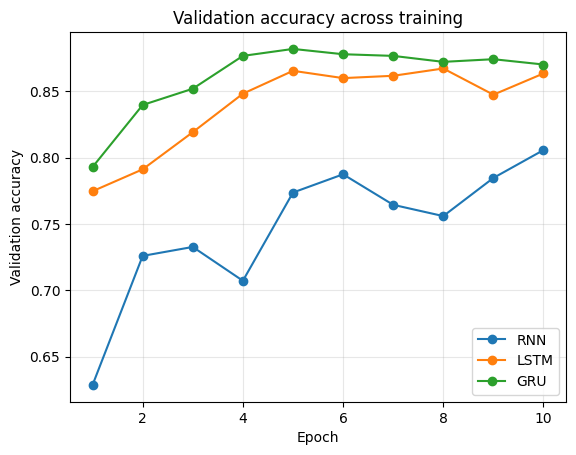

In [56]:
import matplotlib.pyplot as plt  # Plot how accuracy changes across the training epochs.

for name, history in histories.items():  # Plot one line for each model.
    plt.plot(history["epoch"], history["val_acc"], marker="o", label=name)  # Accuracy at each epoch.
plt.xlabel("Epoch")  # Number of training passes through the data.
plt.ylabel("Validation accuracy")  # Accuracy on reviews not used to update weights.
plt.title("Validation accuracy across training")  # Describe the chart.
plt.legend()  # Identify RNN, LSTM, and GRU lines.
plt.grid(alpha=0.3)  # Make values easier to compare.
plt.show()  # Display the training progress.

## 14. Evaluate the selected model on the test data

The test reviews were not used to train the models or decide which one is best. We evaluate the selected model here to estimate its performance on unseen reviews.

In [57]:
test_loss, test_accuracy = validate(best_model, test_loader)  # Evaluate the selected model once on held-out reviews.
print("Test loss:", round(test_loss, 3))  # Average binary classification loss.
print("Test accuracy:", f"{test_accuracy:.1%}")  # Share of reviews classified correctly.

Test loss: 0.32
Test accuracy: 87.9%


### Confusion matrix

A **confusion matrix** counts correct and incorrect negative/positive predictions. The diagonal contains correct predictions; the other two cells show the mistakes.

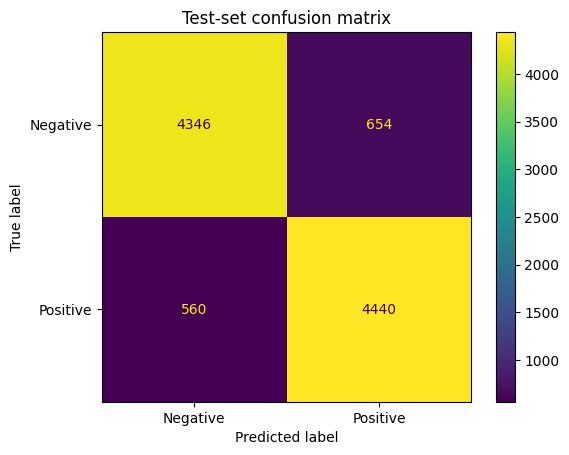

In [58]:
from sklearn.metrics import ConfusionMatrixDisplay  # Plot prediction counts by true class.

true_labels = []  # Store the real sentiments from the test set.
predicted_labels = []  # Store the model's predicted sentiments.
best_model.eval()  # Switch to evaluation behavior.
with torch.no_grad():  # Turn off gradient calculations.
    for ids, lengths, labels in test_loader:  # Visit all test reviews.
        ids = ids.to(device)  # Match the model's device.
        lengths = lengths.to(device)  # Keep real word counts on that device.
        logits = best_model(ids, lengths)  # Produce raw scores.
        predictions = (logits >= 0).int()  # Logits >= 0 predict positive.
        true_labels.extend(labels.int().tolist())  # Save true classes on CPU.
        predicted_labels.extend(predictions.cpu().tolist())  # Move predictions to CPU and save them.

ConfusionMatrixDisplay.from_predictions(  # Draw actual class counts.
    true_labels, predicted_labels, display_labels=["Negative", "Positive"]
)
plt.title("Test-set confusion matrix")  # Title of the chart.
plt.show()  # Display the confusion matrix.

## 15. Predict sentiment for a new review

New text must go through the **same tokenization, vocabulary, padding, and length handling** as the training reviews. We then convert the model's raw score into `P(positive)` using sigmoid.

In [59]:
def predict(text):  # Predict the sentiment of one new review.
    ids, length = encode_review(text)  # Tokenize and encode it exactly as during training.
    ids = torch.tensor([ids], dtype=torch.long).to(device)  # Make a batch of one review.
    lengths = torch.tensor([length], dtype=torch.long).to(device)  # Record its true word count.
    best_model.eval()  # Use inference mode.
    with torch.no_grad():  # No learning is needed for a new prediction.
        logit = best_model(ids, lengths)[0]  # Predict one raw sentiment score.
        probability = torch.sigmoid(logit).item()  # Convert to probability of positive.
    label = "Positive" if probability >= 0.5 else "Negative"  # Apply the 0.5 threshold.
    return label, probability  # Give back the class and probability.

new_review = "The movie was not good."  # Try a sample sentence.
label, probability = predict(new_review)  # Ask our trained model to classify it.
print("Review:", new_review)  # The original input sentence.
print("Predicted sentiment:", label)  # Positive or Negative.
print("Probability of positive:", round(probability, 3))  # Confidence-like estimated probability.

Review: The movie was not good.
Predicted sentiment: Negative
Probability of positive: 0.267


## Pretrained GloVe embeddings (optional)

So far, the LSTM learned its word vectors from **randomly initialized embeddings** using the IMDb training reviews.

**GloVe** provides word vectors learned previously from a much larger text collection. We can put those vectors into a **new LSTM** before training it on IMDb.

- Our original LSTM and the GloVe LSTM both use **100-dimensional embeddings** and the same training/validation data.
- A word absent from GloVe keeps its normal randomly initialized vector.
- The GloVe vectors are **fine-tuned** during IMDb training; they are not frozen.
- Pretrained vectors may help, but better validation accuracy is **not guaranteed**.

This experiment uses the Kaggle GloVe dataset you attached. Run the cells below **after** the original LSTM has finished training.

In [60]:
# GLOVE_PATH = "/kaggle/input/datasets/rtatman/glove-global-vectors-for-word-representation/glove.6B.100d.txt"  # Pretrained 100-number word vectors.

GLOVE_PATH = "/kaggle/input/datasets/faridhasan007/rtatman/glove.6B.100d.txt" # from my PC preloaded

torch.manual_seed(42)  # Start the new LSTM with the same initialization seed as the original LSTM.
glove_lstm = SentimentClassifier(nn.LSTM)  # Create a new LSTM; do not overwrite the original trained model.
matched_words = 0  # Count vocabulary words for which GloVe provides a vector.

with torch.no_grad():  # Directly setting initial weights should not calculate gradients.
    with open(GLOVE_PATH, encoding="utf-8") as glove_file:  # Read pretrained vectors from Kaggle.
        for line in glove_file:  # Each line contains one word and its 100 numbers.
            word, values = line.strip().split(" ", 1)  # Separate the word from its vector values.
            if word in word2idx and word2idx[word] >= 2:  # Skip words not in our vocabulary and special tokens.
                word_id = word2idx[word]  # Find where this word is stored in our embedding layer.
                vector = [float(number) for number in values.split()]  # Convert the 100 values from text to numbers.
                glove_lstm.embedding.weight[word_id] = torch.tensor(vector)  # Replace the initial vector with GloVe.
                matched_words += 1  # Record that we found one matching word.

print("Vocabulary words with GloVe vectors:", matched_words)  # How many useful vectors were loaded.
print("Vocabulary coverage:", f"{matched_words / (len(word2idx) - 2):.1%}")  # Fraction of normal vocabulary words covered.
print("Embedding shape:", tuple(glove_lstm.embedding.weight.shape))  # (vocabulary size, 100).
print("Embeddings will keep learning:", glove_lstm.embedding.weight.requires_grad)  # True means GloVe vectors can be fine-tuned.

Vocabulary words with GloVe vectors: 9838
Vocabulary coverage: 98.4%
Embedding shape: (10002, 100)
Embeddings will keep learning: True


### Train the GloVe-initialized LSTM

We use the **same** `fit()` function, epochs, optimizer, training data, and validation data as before. The key difference is how the word embeddings were **initialized**. The embeddings will continue changing when the LSTM trains.

In [61]:
glove_lstm, glove_history = fit(glove_lstm, "LSTM + GloVe")  # Fine-tune the pretrained vectors and train the classifier.
display(glove_history.round(3))  # Show training loss and validation results for each epoch.

LSTM + GloVe | Epoch 01/10: train loss=0.542, validation loss=0.387, validation accuracy=84.0%
LSTM + GloVe | Epoch 02/10: train loss=0.336, validation loss=0.305, validation accuracy=87.8%
LSTM + GloVe | Epoch 03/10: train loss=0.256, validation loss=0.310, validation accuracy=87.5%
LSTM + GloVe | Epoch 04/10: train loss=0.204, validation loss=0.302, validation accuracy=87.2%
LSTM + GloVe | Epoch 05/10: train loss=0.162, validation loss=0.334, validation accuracy=87.7%
LSTM + GloVe | Epoch 06/10: train loss=0.129, validation loss=0.360, validation accuracy=87.1%
LSTM + GloVe | Epoch 07/10: train loss=0.097, validation loss=0.395, validation accuracy=87.4%
LSTM + GloVe | Epoch 08/10: train loss=0.072, validation loss=0.464, validation accuracy=87.0%
LSTM + GloVe | Epoch 09/10: train loss=0.053, validation loss=0.516, validation accuracy=87.1%
LSTM + GloVe | Epoch 10/10: train loss=0.041, validation loss=0.597, validation accuracy=86.8%


,epoch,train_loss,val_loss,val_acc
0,1,0.542,0.387,0.840
1,2,0.336,0.305,0.878
2,3,0.256,0.310,0.875
3,4,0.204,0.302,0.872
4,5,0.162,0.334,0.877
5,6,0.129,0.360,0.870
6,7,0.097,0.395,0.874
7,8,0.072,0.464,0.870
8,9,0.053,0.516,0.871
9,10,0.041,0.597,0.868


### Compare: LSTM from scratch vs. LSTM with GloVe

Compare the **best validation epoch** for each LSTM. We do **not** use the test set to choose which embedding initialization is better. Different results do not prove that pretrained embeddings are always better or worse.

# scratch_best = lstm_history.loc[lstm_history["val_loss"].idxmin()]  # Lowest validation loss for the original LSTM.
glove_best = glove_history.loc[glove_history["val_loss"].idxmin()]  # Lowest validation loss for the GloVe LSTM.

embedding_comparison = pd.DataFrame({  # Put the two results in a small comparison table.
    "Embedding": ["Learned from scratch", "Pretrained GloVe (fine-tuned)"],  # How the vectors were initialized.
    "Best epoch": [int(scratch_best["epoch"]), int(glove_best["epoch"])],  # Epoch of each model's lowest validation loss.
    "Validation loss": [scratch_best["val_loss"], glove_best["val_loss"]],  # Lower is better.
    "Validation accuracy": [scratch_best["val_acc"], glove_best["val_acc"]],  # Higher is better.
})

display(embedding_comparison.round(3))  # Show measured results, not assumed performance.

## 16. Save the GRU artifacts for the FastAPI project (Project 07)

Saves the trained GRU weights, the training vocabulary, and the model configuration from this same run. Download the three files in `artifacts/` and put them in the API project's `artifacts/` folder.

In [ ]:
import os
import json
import torch

# gru_model already holds its best-validation-epoch weights (restored at the end of fit()).
VOCAB_SIZE = len(word2idx)   # 10,000 words + <PAD> + <UNK> = 10,002
EMBED_DIM = 100              # nn.Embedding(len(word2idx), 100)
HIDDEN_SIZE = 64             # recurrent_layer(100, 64)
NUM_LAYERS = 1               # single-layer GRU
# MAX_LEN = 200 is already defined earlier in the notebook

os.makedirs("artifacts", exist_ok=True)
torch.save(gru_model.state_dict(), "artifacts/gru_model.pt")

with open("artifacts/word2idx.json", "w") as f:
    json.dump(word2idx, f)

config = {
    "vocab_size": VOCAB_SIZE,
    "embed_dim": EMBED_DIM,
    "hidden_size": HIDDEN_SIZE,
    "num_layers": NUM_LAYERS,
    "max_len": MAX_LEN,
}
with open("artifacts/config.json", "w") as f:
    json.dump(config, f, indent=2)

print("Saved:", os.listdir("artifacts"))
print(config)


In [ ]:
# Reference predictions from the notebook -- the API must return the same numbers.
# (The notebook's predict() uses best_model, which may not be the GRU, so we call gru_model directly.)
def gru_predict(text):
    ids, length = encode_review(text)
    ids = torch.tensor([ids], dtype=torch.long).to(device)
    lengths = torch.tensor([length], dtype=torch.long).to(device)
    gru_model.eval()
    with torch.no_grad():
        p = torch.sigmoid(gru_model(ids, lengths)[0]).item()
    return ("POSITIVE", p) if p >= 0.5 else ("NEGATIVE", 1 - p)

for t in ["This movie was absolutely amazing!",
          "The movie was not good.",
          "A complete waste of time. Terrible acting and a boring plot."]:
    label, conf = gru_predict(t)
    print(f"{label:8s} {conf:.4f}  <- {t}")
